In [3]:
import scanpy as sc
import numpy as np

sc.settings.verbosity = 2
sc.settings.set_figure_params(dpi=100, figsize=(8, 6), facecolor="white")
print(sc.__version__)

1.11.5


C:\Users\anura\AppData\Local\Temp\ipykernel_39432\3563109522.py:6: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print(sc.__version__)


In [5]:
import urllib.request, tarfile, os

url = "https://www.ncbi.nlm.nih.gov/geo/download/?acc=GSE132188&format=file"
os.makedirs("data/GSE132188_RAW", exist_ok=True)
urllib.request.urlretrieve(url, "data/GSE132188_RAW.tar")

with tarfile.open("data/GSE132188_RAW.tar") as tar:
    tar.extractall("data/GSE132188_RAW")

for f in sorted(os.listdir("data/GSE132188_RAW")):
    print(f)

C:\Users\anura\AppData\Local\Temp\ipykernel_39432\757709686.py:8: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall("data/GSE132188_RAW")


GSM3852752_E12_5_counts.tar.gz
GSM3852753_E13_5_counts.tar.gz
GSM3852754_E14_5_counts.tar.gz
GSM3852755_E15_5_counts.tar.gz


In [6]:
import tarfile, os

path = "data/GSE132188_RAW/GSM3852755_E15_5_counts.tar.gz"
with tarfile.open(path) as tar:
    tar.extractall("data/E15_5")

for root, dirs, files in os.walk("data/E15_5"):
    for f in files:
        print(os.path.join(root, f))

C:\Users\anura\AppData\Local\Temp\ipykernel_39432\96865704.py:5: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall("data/E15_5")


data/E15_5\mm10\barcodes.tsv
data/E15_5\mm10\genes.tsv
data/E15_5\mm10\matrix.mtx


Load data

In [7]:
adata = sc.read_10x_mtx("data/E15_5/mm10/", var_names="gene_symbols", cache=True)
adata.var_names_make_unique()
adata

... writing an h5ad cache file to speedup reading next time


AnnData object with n_obs × n_vars = 11439 × 27998
    var: 'gene_ids'

Quality control

In [8]:
adata.var["mt"] = adata.var_names.str.startswith("mt-")
print(adata.var["mt"].sum(), "mito genes found")

sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)
adata.obs[["total_counts", "n_genes_by_counts", "pct_counts_mt"]].describe()

13 mito genes found


,total_counts,n_genes_by_counts,pct_counts_mt
count,11439.000000,11439.000000,11439.000000
mean,16180.711914,3449.280706,2.502014
std,8644.794922,874.693604,1.184562
min,4060.000000,165.000000,0.088552
25%,8243.000000,2763.500000,1.915807
50%,15602.000000,3423.000000,2.344854
75%,21991.000000,4093.000000,2.876442
max,72929.000000,6618.000000,28.337626


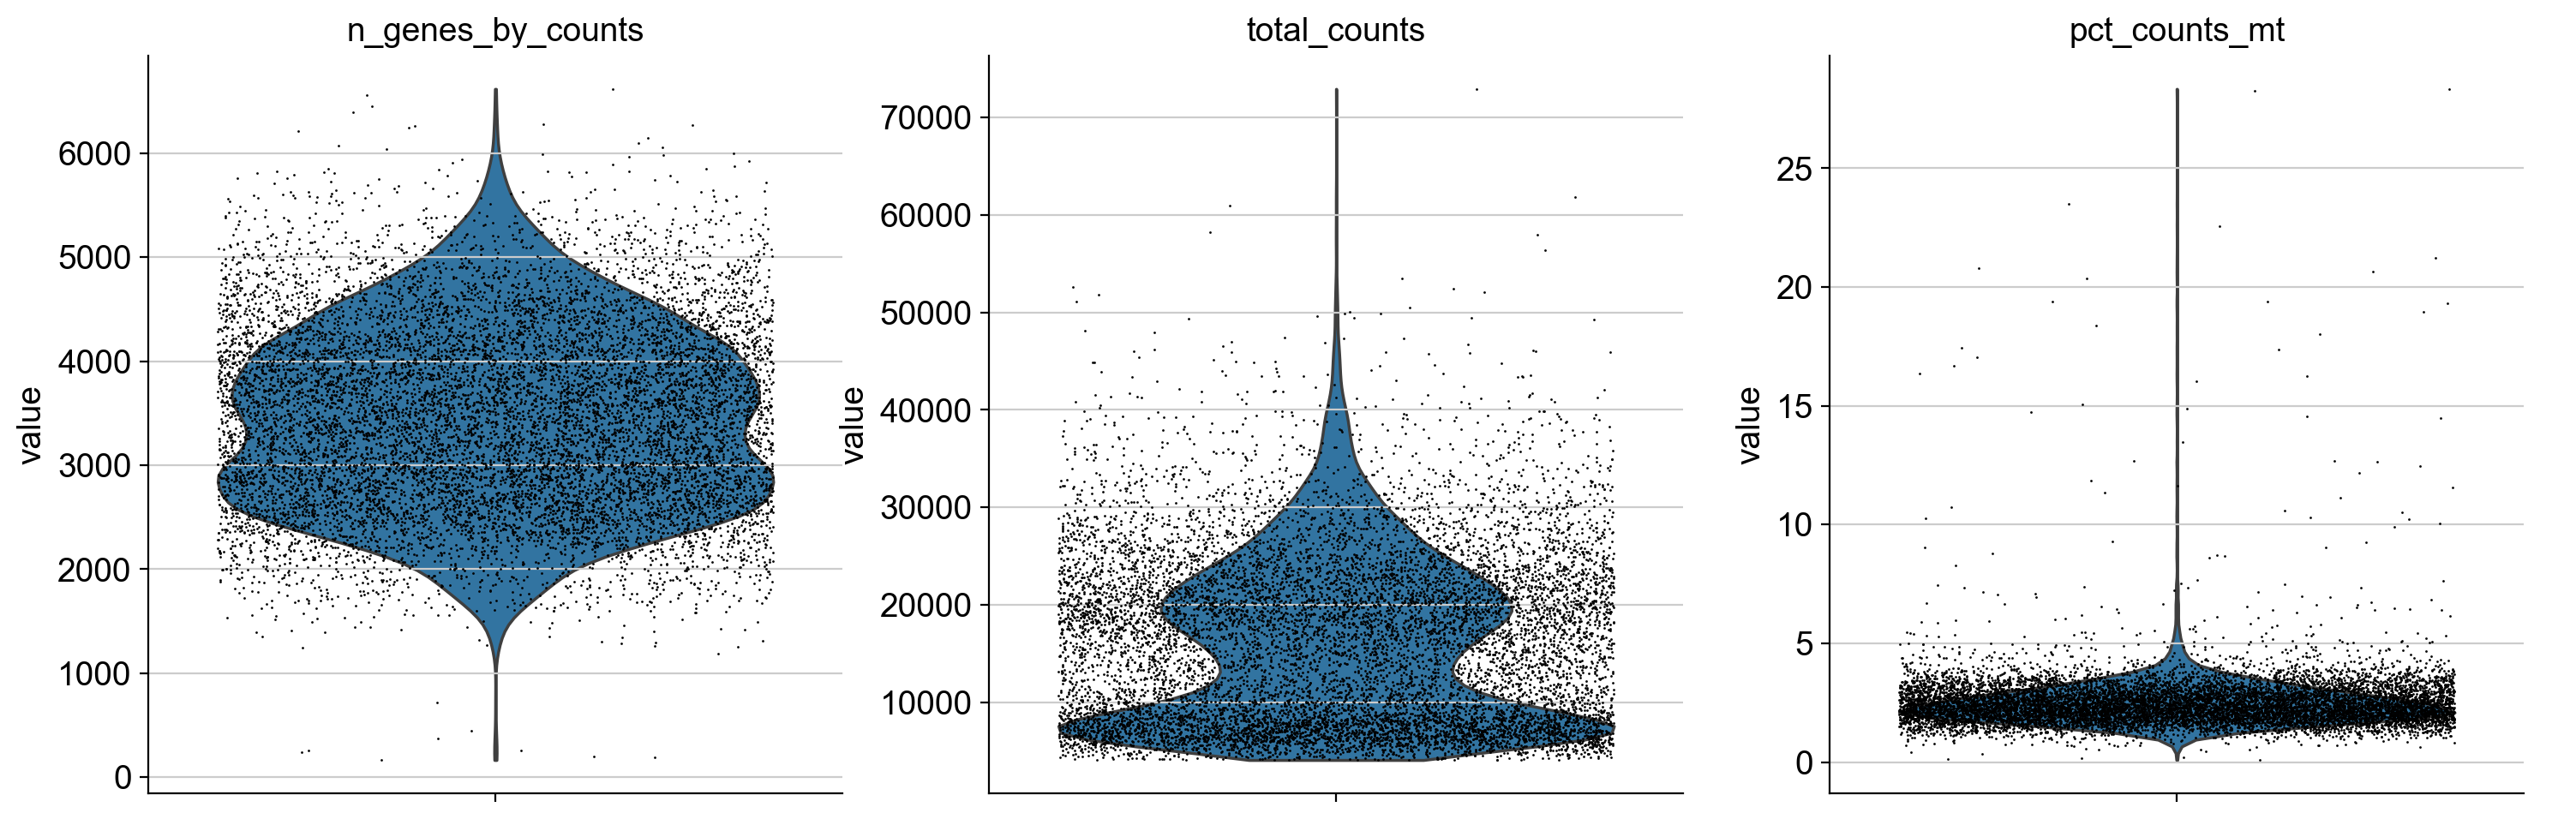

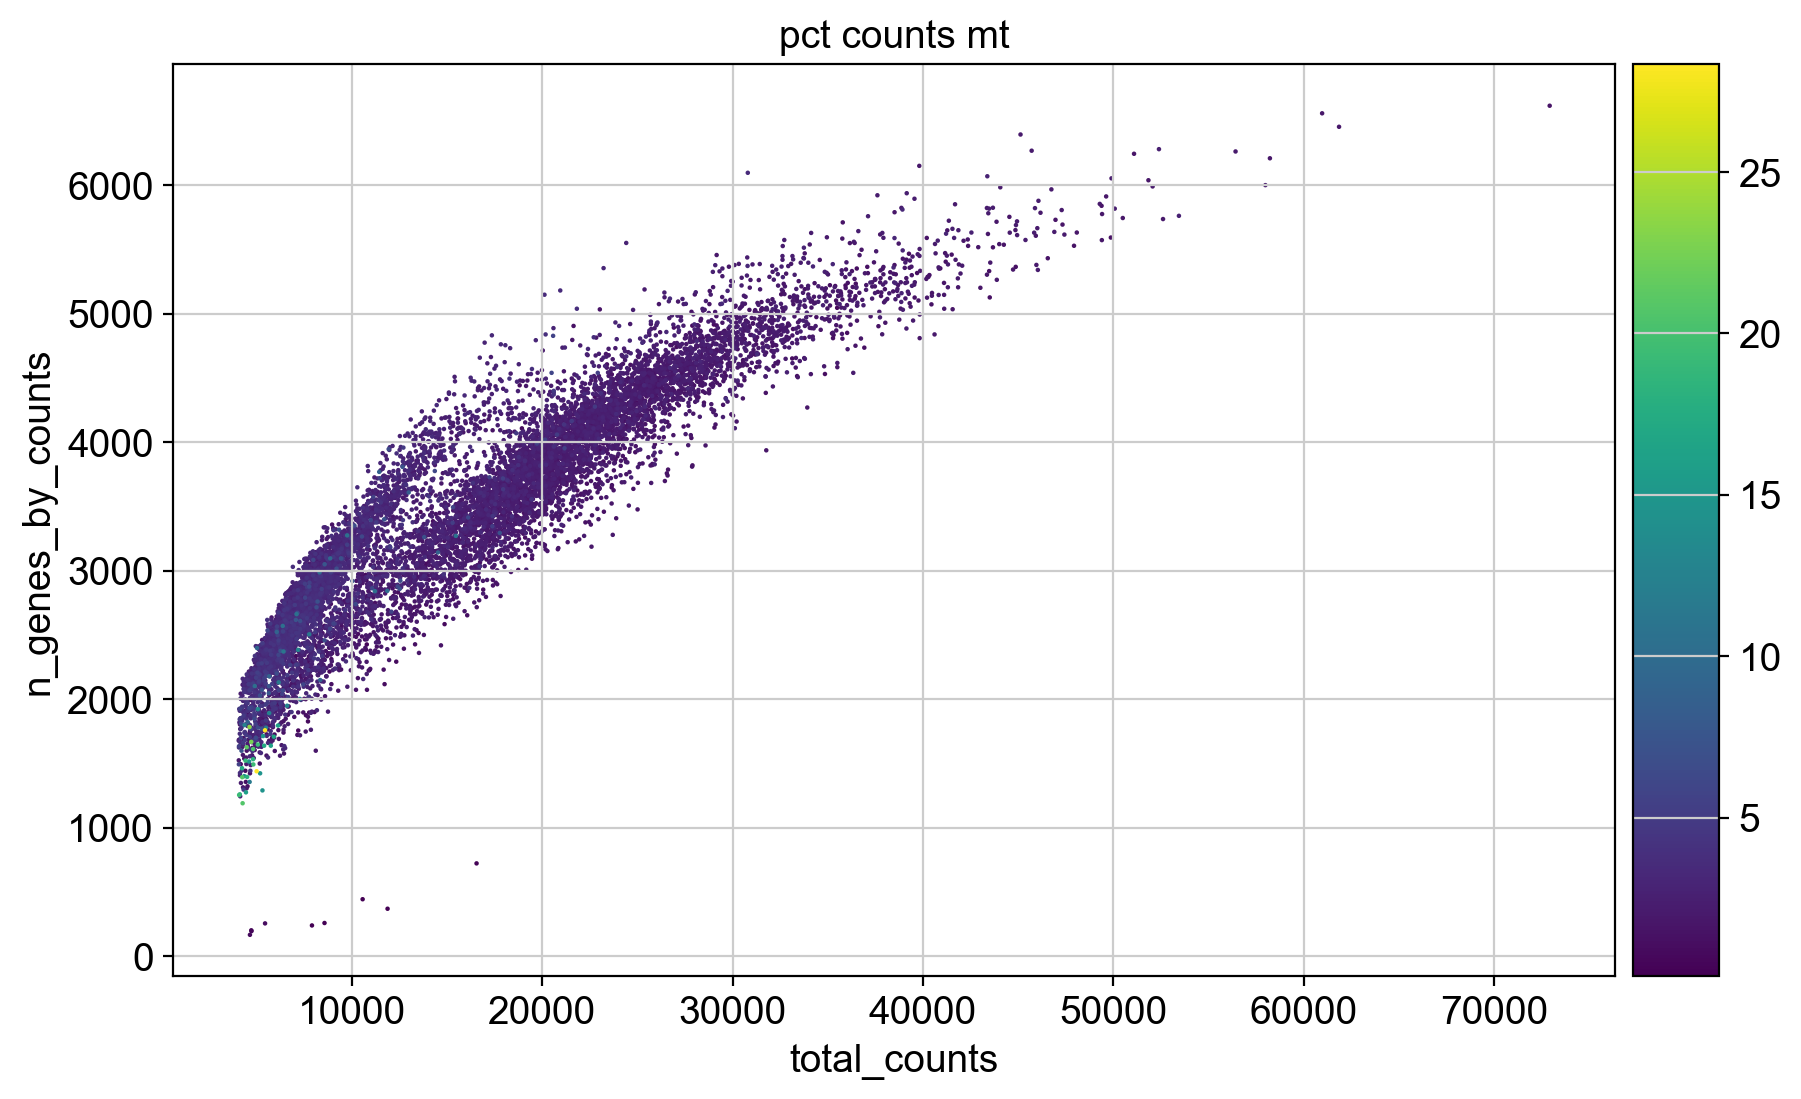

In [9]:
sc.pl.violin(adata, ["n_genes_by_counts", "total_counts", "pct_counts_mt"], jitter=0.4, multi_panel=True)
sc.pl.scatter(adata, x="total_counts", y="n_genes_by_counts", color="pct_counts_mt")

Cutoff choosing

In [10]:
low_genes = adata.obs["n_genes_by_counts"] < 1000
high_mt = adata.obs["pct_counts_mt"] > 10
high_counts = adata.obs["total_counts"] > 50000
fail_any = low_genes | high_mt | high_counts

print(low_genes.sum(), "cells with too few genes")
print(high_mt.sum(), "cells with high mito %")
print(high_counts.sum(), "cells with very high counts")
print(fail_any.sum(), "cells fail at least one rule")

9 cells with too few genes
44 cells with high mito %
14 cells with very high counts
67 cells fail at least one rule


Filtering

In [11]:
adata = adata[~fail_any].copy()
sc.pp.filter_genes(adata, min_cells=10)
adata.layers["counts"] = adata.X.copy()
adata

filtered out 11823 genes that are detected in less than 10 cells


AnnData object with n_obs × n_vars = 11372 × 16175
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    layers: 'counts'

Normalisation

In [12]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
print("max after normalization:", adata.X.max())

normalizing counts per cell
    finished (0:00:00)
max after normalization: 7.740884


Highly variable genes

In [13]:
sc.pp.highly_variable_genes(adata, n_top_genes=2000)
print(adata.var["highly_variable"].sum(), "highly variable genes selected")

extracting highly variable genes
    finished (0:00:00)
2000 highly variable genes selected


PCA

computing PCA
    with n_comps=50
    finished (0:00:01)


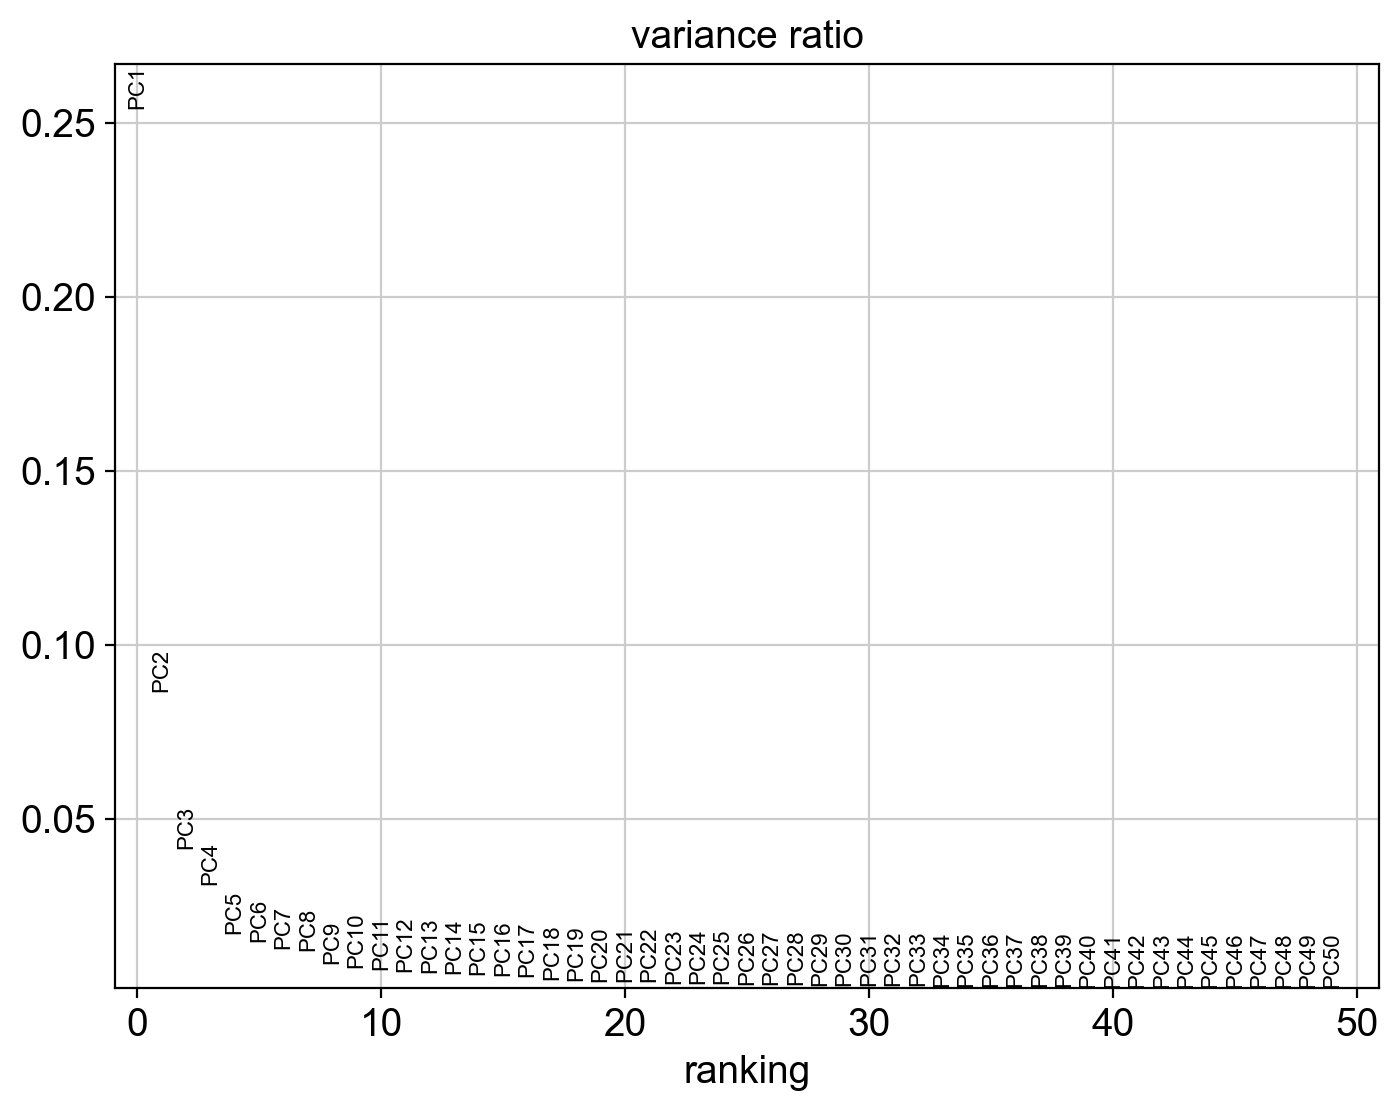

In [14]:
sc.tl.pca(adata, n_comps=50)
sc.pl.pca_variance_ratio(adata, n_pcs=50)

Neighbors and UMAP

computing neighbors
    using 'X_pca' with n_pcs = 30
    finished (0:00:41)
computing UMAP
    finished (0:00:05)


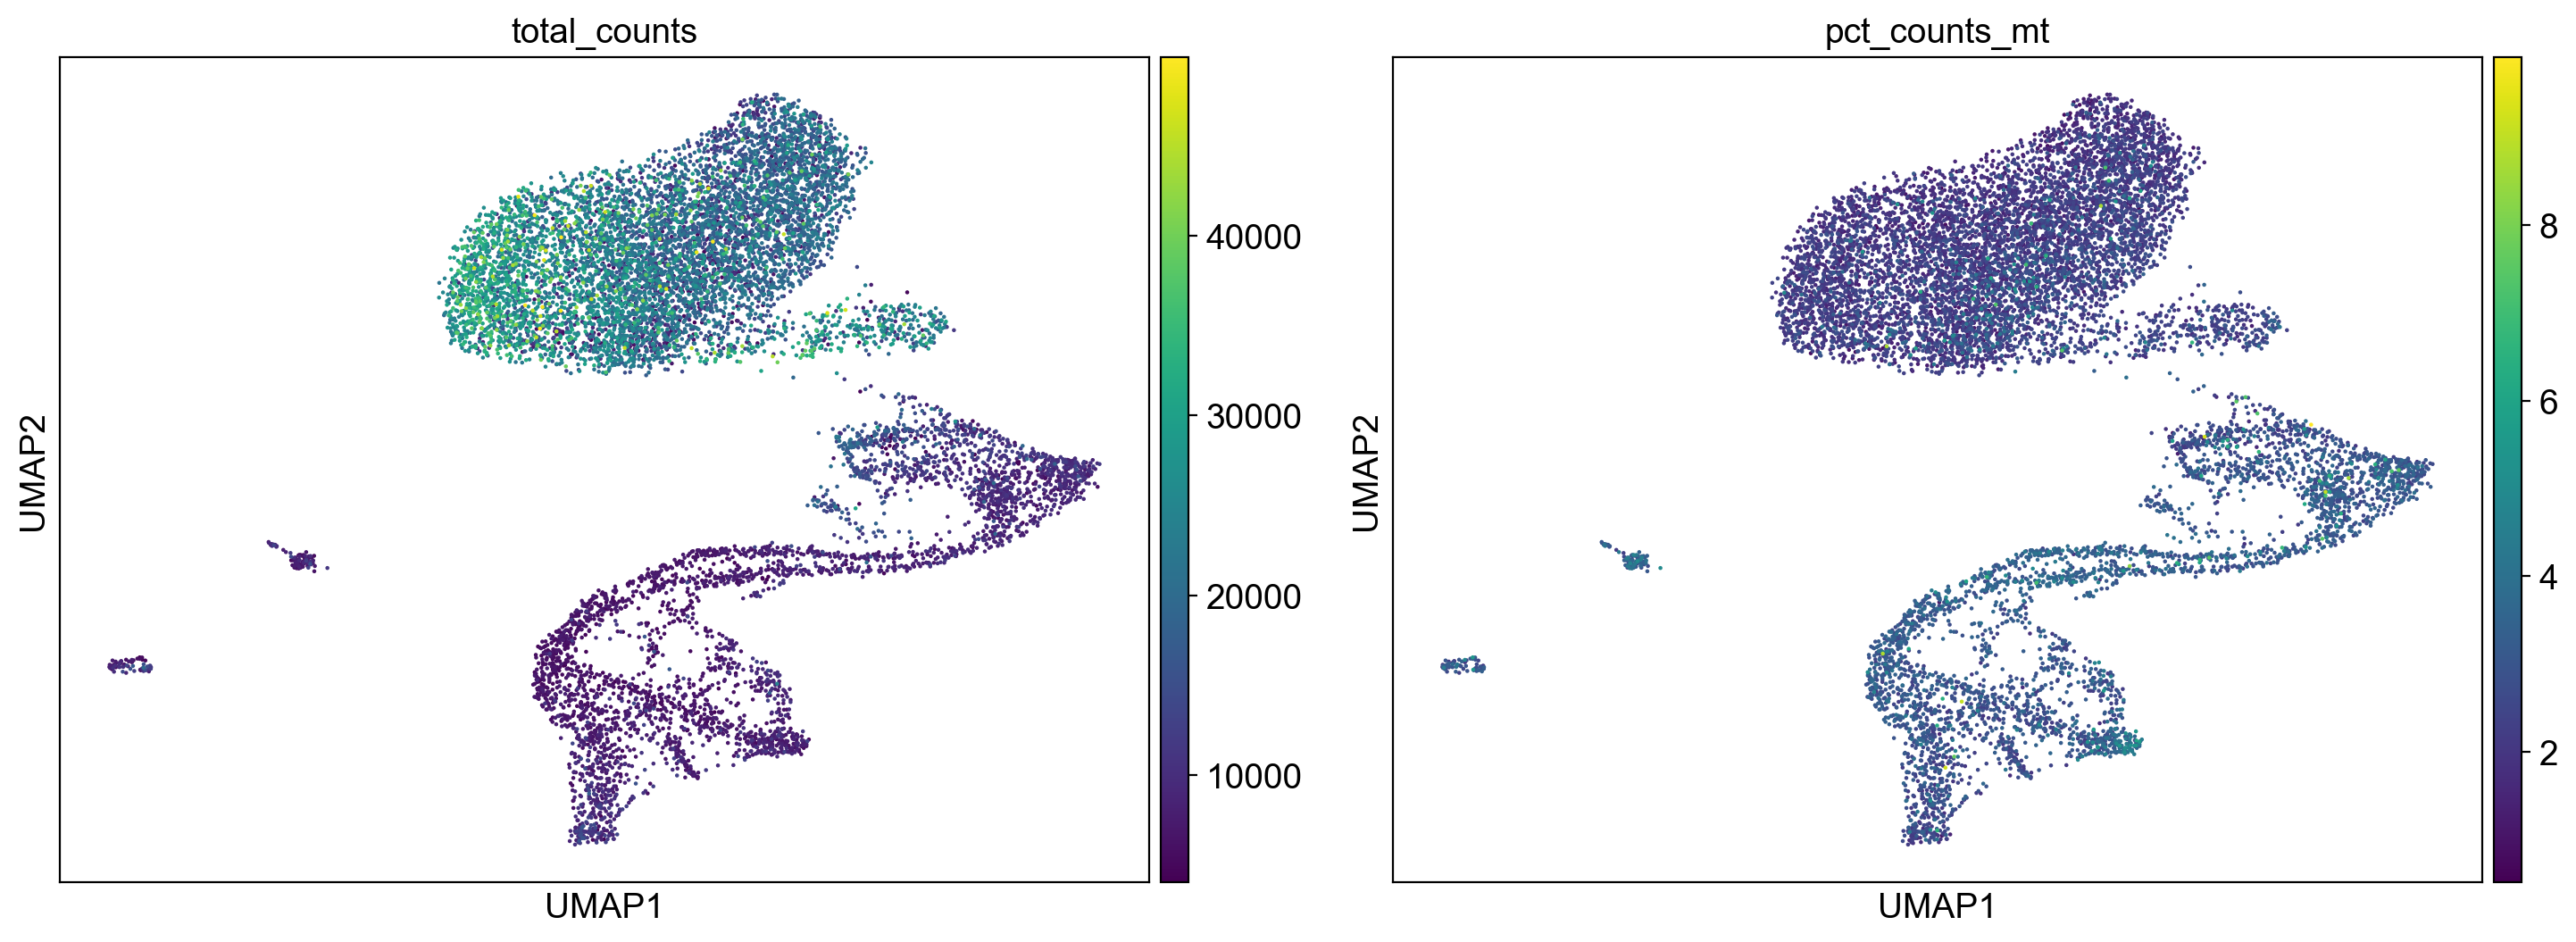

In [15]:
sc.pp.neighbors(adata, n_neighbors=30, n_pcs=30)
sc.tl.umap(adata)
sc.pl.umap(adata, color=["total_counts", "pct_counts_mt"])

Clustering

running Leiden clustering
    finished (0:00:00)


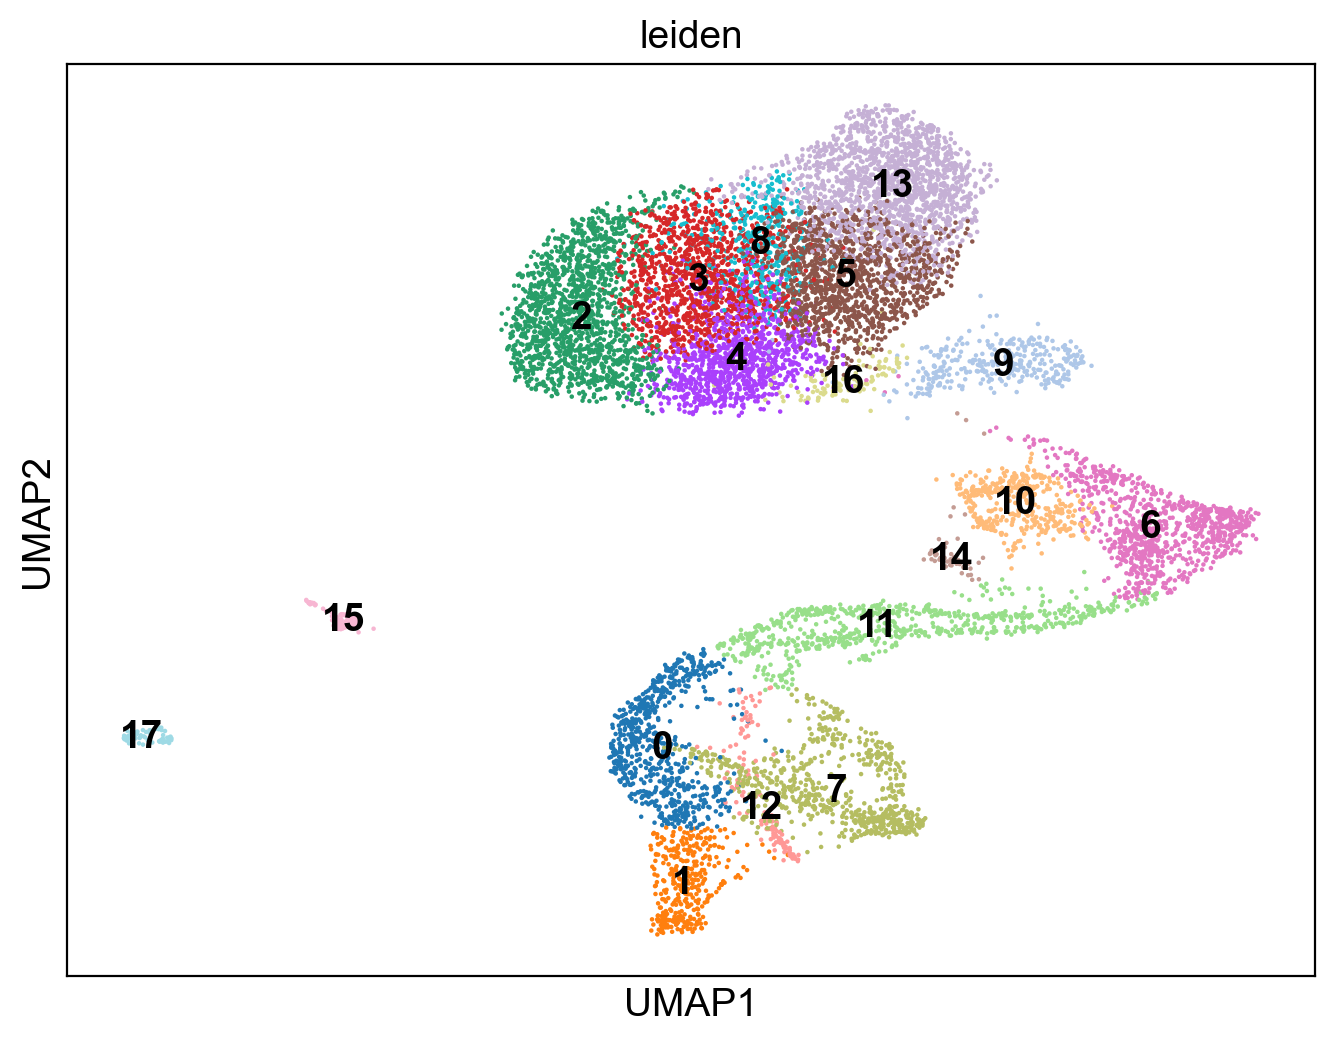

In [16]:
sc.tl.leiden(adata, resolution=1.0, flavor="igraph", n_iterations=2)
sc.pl.umap(adata, color="leiden", legend_loc="on data")

Marker genes per cluster

In [17]:
import pandas as pd

sc.tl.rank_genes_groups(adata, groupby="leiden", method="wilcoxon")
top_genes = pd.DataFrame(adata.uns["rank_genes_groups"]["names"]).head(5)
top_genes

ranking genes
    finished (0:00:11)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
0,Hmgn3,Iapp,Ube2c,Rrm2,Npm1,Nupr1,Spp1,Cpe,Cdc20,Vwa5b2,Hmgb2,Neurog3,Isl1,Ctrb1,Spp1,Itm2a,Spp1,Tmsb4x
1,Chgb,Ins2,Cks2,Hist1h2ap,Ran,Rpl10,Sparc,Aplp1,Cenpa,Hmgn3,Spp1,Sox4,Meg3,Clps,Sox9,Lgals1,Bicc1,Tyrobp
2,Fev,Gng12,Birc5,2810417H13Rik,Hspd1,Rpl3,Anxa2,Tmem27,Ccnb2,Aplp1,Bicc1,Btbd17,Pyy,Try10,Tinagl1,Sparc,Adamts1,Laptm5
3,Chga,Nnat,Cdk1,Pcna,Ptma,Rps2,Bicc1,Fam183b,Tubb4b,Cck,Tubb5,Mtch1,Hhex,Spink1,Atp1b1,Gas1,Tinagl1,Ctss
4,Cryba2,Pcsk2,Top2a,Gmnn,Rps2,Gstm1,Atp1b1,Gnas,Serp1,Pax6,1700011H14Rik,Marcksl1,Malat1,Pnliprp1,Bicc1,Rcn3,Sparc,B2m


Reference Annotation ((authors' data)

In [18]:
import urllib.request

url = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE132nnn/GSE132188/suppl/GSE132188_adata.h5ad.h5"
urllib.request.urlretrieve(url, "data/GSE132188_adata.h5ad")

ref = sc.read_h5ad("data/GSE132188_adata.h5ad")
print(ref)
print(ref.obs_names[:5].tolist())
print("max value in X:", ref.X.max())

C:\Users\anura\AppData\Roaming\Python\Python313\site-packages\anndata\compat\__init__.py:371: FutureWarning: Moving element from .uns['neighbors']['distances'] to .obsp['distances'].

This is where adjacency matrices should go now.
  warn(
C:\Users\anura\AppData\Roaming\Python\Python313\site-packages\anndata\compat\__init__.py:371: FutureWarning: Moving element from .uns['neighbors']['connectivities'] to .obsp['connectivities'].

This is where adjacency matrices should go now.
  warn(


AnnData object with n_obs × n_vars = 36351 × 17327
    obs: 'day', 'n_counts', 'log_counts', 'n_genes', 'mt_frac', 'proliferation', 'G2M_score', 'S_score', 'clusters_fig3_final', 'clusters_fig3_final_noep', 'clusters_fig4_final', 'clusters_fig2_final', 'clusters_fig6_broad_final', 'clusters_fig6_fine_final', 'clusters_fig6_alpha_final'
    var: 'n_cells', 'highly_variable_genes', 'expression_mean', 'dispersion'
    uns: 'Ngn3+_colors', 'PCs_loading_hvg', 'clusters_fig2_final_colors', 'clusters_fig3_final_colors', 'clusters_fig3_final_noep_colors', 'clusters_fig4_final_colors', 'clusters_fig6_alpha_final_colors', 'clusters_fig6_broad_final_colors', 'clusters_fig6_fine_final_colors', 'day_colors', 'neighbors', 'pca', 'proliferation_colors'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'
['AAACCTGAGCACCGCT-1-0', 'AAACCTGAGCGCTTAT-1-0', 'AAACCTGAGGGAAACA-1-0', 'AAACCTGAGGTACTCT-1-0', 'AAACCTGAGTCACGCC-1-0']
max value in X: 28.987896


In [19]:
ref.obs["sample"] = ref.obs_names.str.split("-").str[-1]
print(pd.crosstab(ref.obs["sample"], ref.obs["day"]))

for col in ["clusters_fig2_final", "clusters_fig3_final", "clusters_fig6_broad_final"]:
    print("\n", col)
    print(ref.obs[col].value_counts())

day      12.5  13.5  14.5   15.5
sample                          
0       10790     0     0      0
1           0  5042     0      0
2           0     0  9633      0
3           0     0     0  10886

 clusters_fig2_final
clusters_fig2_final
Acinar           10432
Ductal            6575
Tip               6105
EP                5119
Endocrine         2999
Fev+              2058
Trunk             1838
Multipotent       1225
Other/Doublet        0
Name: count, dtype: int64

 clusters_fig3_final
clusters_fig3_final
Mat. Acinar      7067
Ductal           4268
Tip              3821
Prlf. Acinar     3365
Endocrine        2999
Ngn3 low EP      2616
Ngn3 high EP     2503
Prlf. Ductal     2307
Prlf. Tip        2284
Fev+             2058
Multipotent      1225
Prlf. Trunk      1205
Trunk             633
Other/Doublet       0
Name: count, dtype: int64

 clusters_fig6_broad_final
clusters_fig6_broad_final
Mat. Acinar      7067
Ductal           4268
Tip              3821
Prlf. Acinar     3365
Ngn3 low 

{'0': np.int64(150), '1': np.int64(73), '2': np.int64(160), '3': np.int64(10839)}


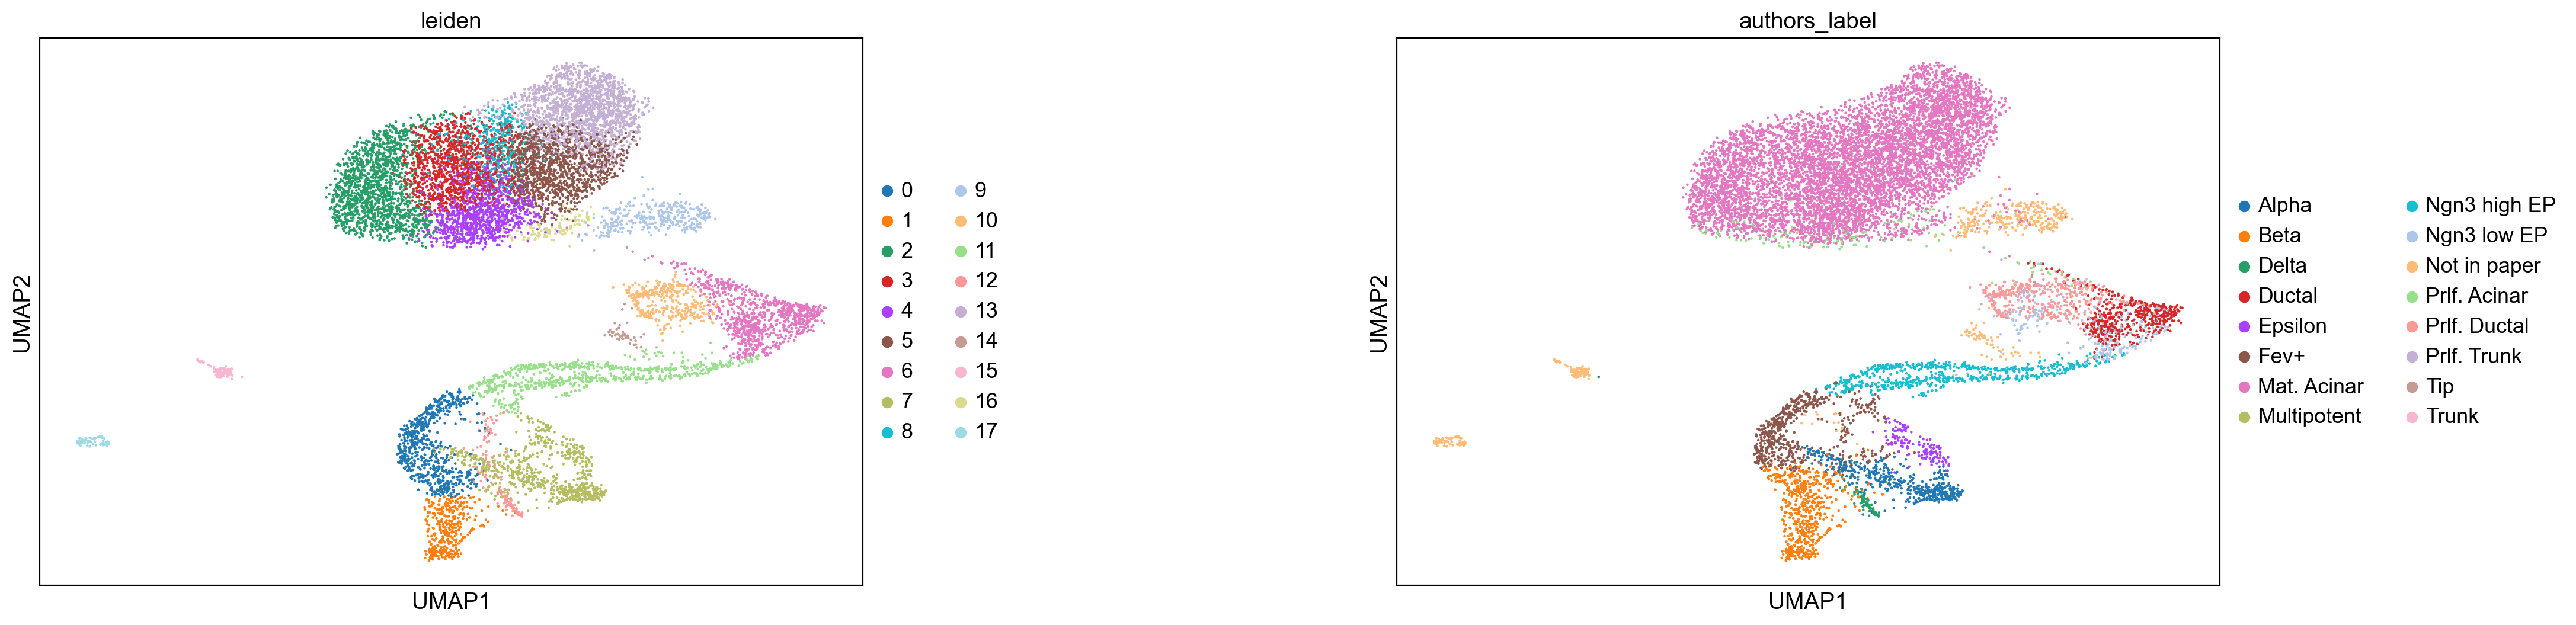

In [20]:
ref.obs["barcode"] = ref.obs_names.str.rsplit("-", n=1).str[0]

overlap = {}
for s in ref.obs["sample"].unique():
    in_sample = ref.obs["sample"] == s
    overlap[s] = ref.obs.loc[in_sample, "barcode"].isin(adata.obs_names).sum()
print(overlap)
best = max(overlap, key=overlap.get)

ref_e15 = ref.obs[ref.obs["sample"] == best]
lookup = dict(zip(ref_e15["barcode"], ref_e15["clusters_fig6_broad_final"]))
adata.obs["authors_label"] = adata.obs_names.map(lookup).fillna("Not in paper")

sc.pl.umap(adata, color=["leiden", "authors_label"], wspace=0.5)

In [21]:
ct = pd.crosstab(adata.obs["leiden"], adata.obs["authors_label"], normalize="index")
summary = pd.DataFrame({"top_label": ct.idxmax(axis=1), "fraction": ct.max(axis=1).round(2)})
summary

,top_label,fraction
leiden,,
0,Fev+,0.66
1,Beta,0.99
2,Mat. Acinar,0.97
3,Mat. Acinar,1.00
4,Mat. Acinar,0.94
5,Mat. Acinar,0.99
6,Ductal,0.56
7,Alpha,0.69
8,Mat. Acinar,1.00


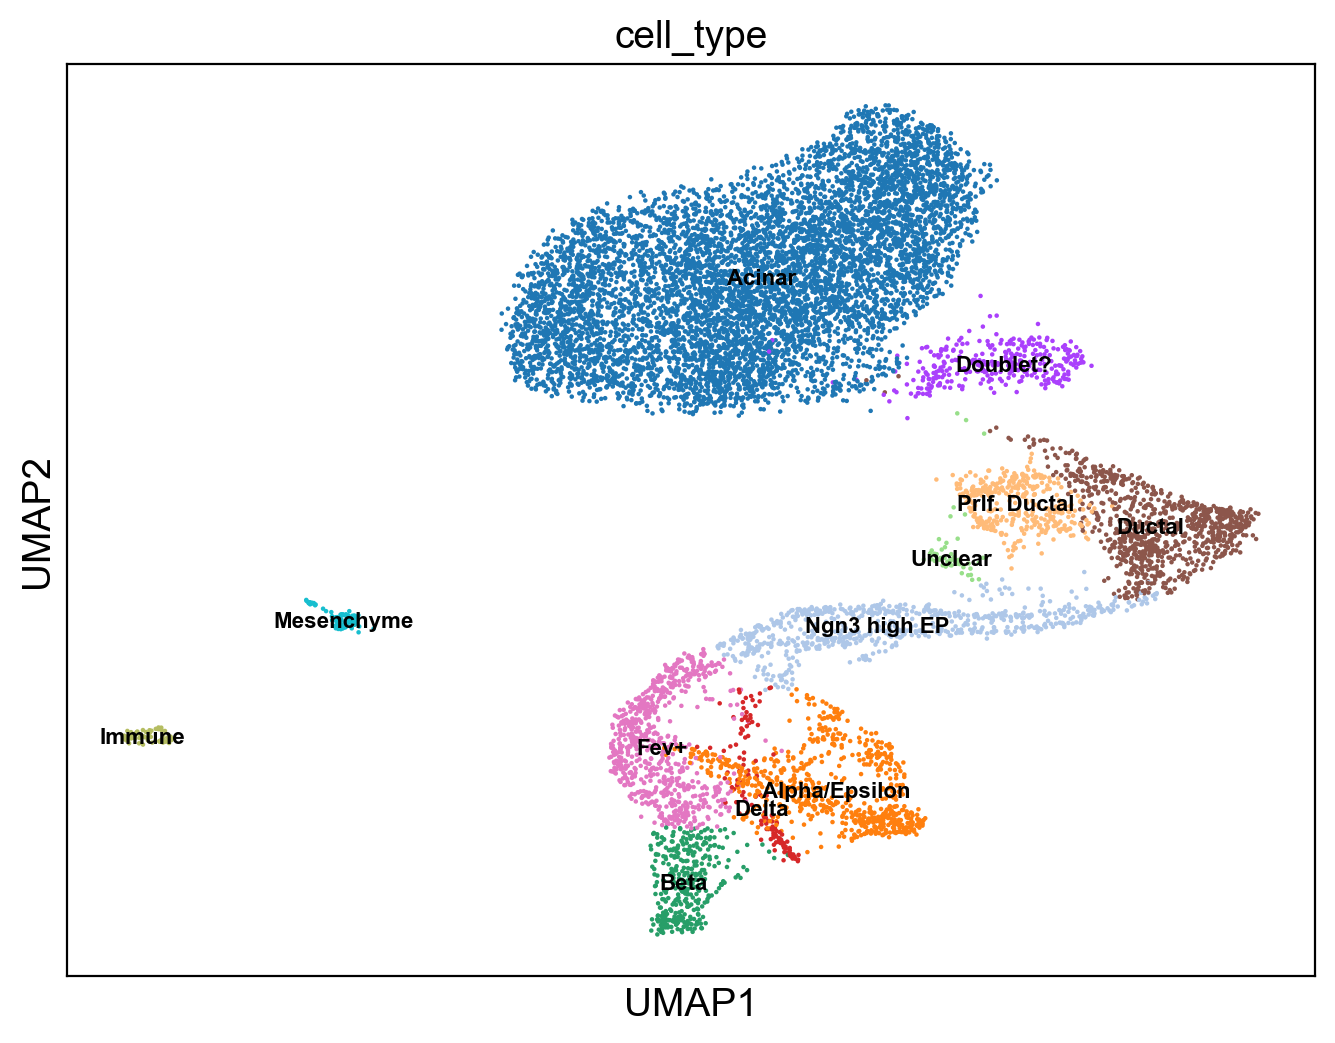

In [22]:
cluster_names = {
    "0": "Fev+", "1": "Beta", "2": "Acinar", "3": "Acinar", "4": "Acinar",
    "5": "Acinar", "6": "Ductal", "7": "Alpha/Epsilon", "8": "Acinar",
    "9": "Doublet?", "10": "Prlf. Ductal", "11": "Ngn3 high EP", "12": "Delta",
    "13": "Acinar", "14": "Unclear", "15": "Mesenchyme", "16": "Acinar", "17": "Immune",
}
adata.obs["cell_type"] = adata.obs["leiden"].map(cluster_names).astype("category")
sc.pl.umap(adata, color="cell_type", legend_loc="on data", legend_fontsize=8)

Trajectory analysis

Subset to endocrine lineage

(3811, 16175)
extracting highly variable genes
    finished (0:00:00)
computing PCA
    with n_comps=30
    finished (0:00:00)
computing neighbors
    using 'X_pca' with n_pcs = 30
    finished (0:00:05)
computing UMAP
    finished (0:00:04)


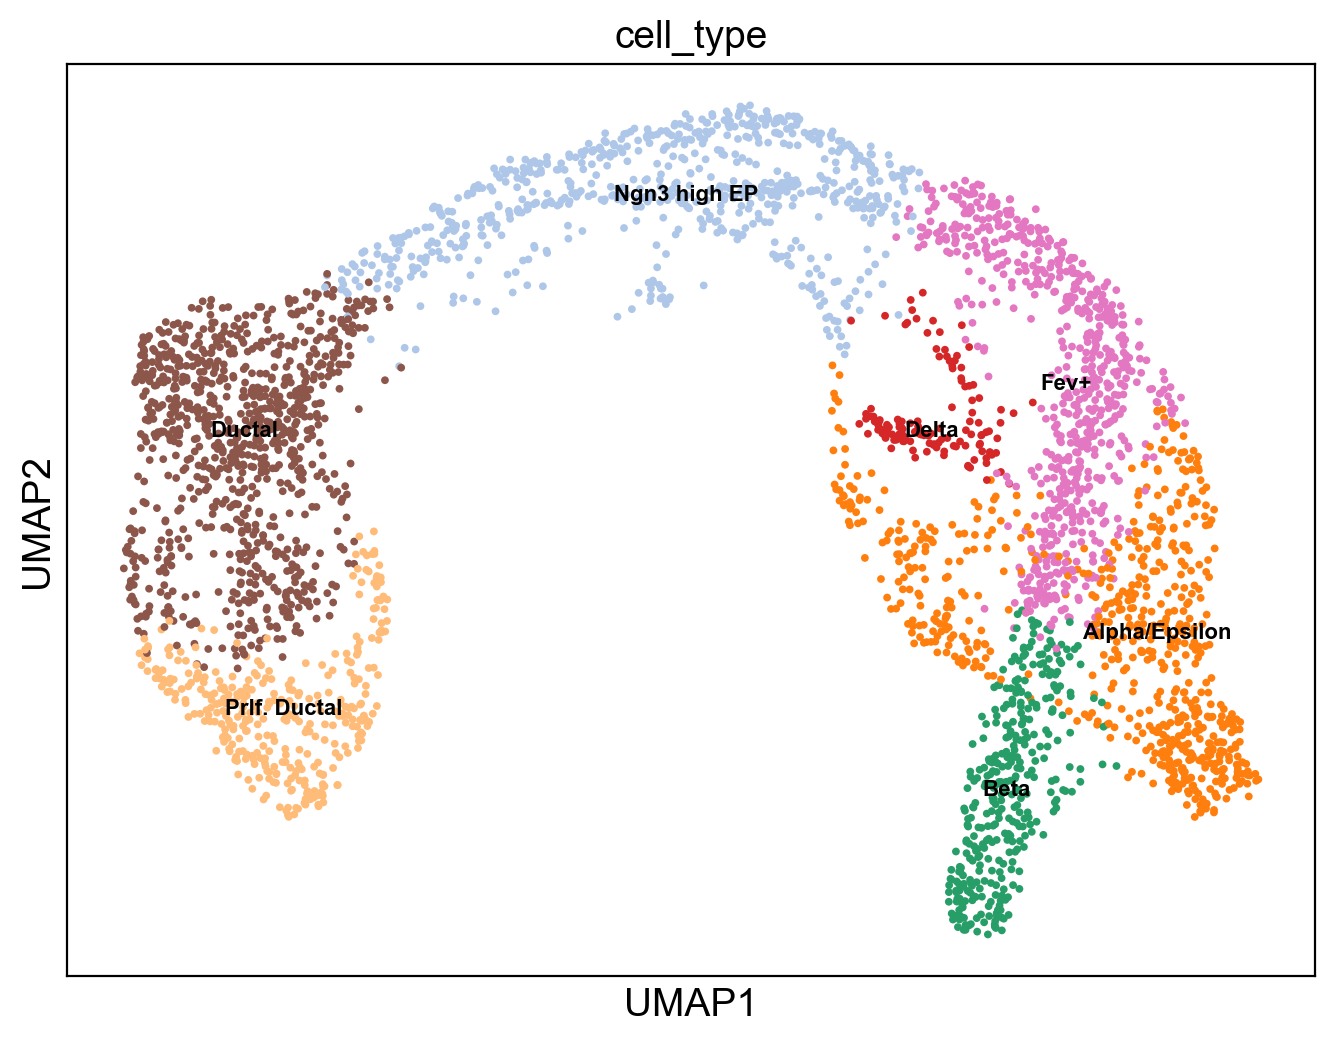

In [23]:
lineage = ["Ductal", "Prlf. Ductal", "Ngn3 high EP", "Fev+", "Alpha/Epsilon", "Delta", "Beta"]
endo = adata[adata.obs["cell_type"].isin(lineage)].copy()
endo.obs["cell_type"] = endo.obs["cell_type"].cat.remove_unused_categories()
print(endo.shape)

sc.pp.highly_variable_genes(endo, n_top_genes=2000)
sc.tl.pca(endo, n_comps=30)
sc.pp.neighbors(endo, n_neighbors=30, n_pcs=30)
sc.tl.umap(endo)
sc.pl.umap(endo, color="cell_type", legend_loc="on data", legend_fontsize=8)

PAGA

running PAGA
    finished (0:00:00)


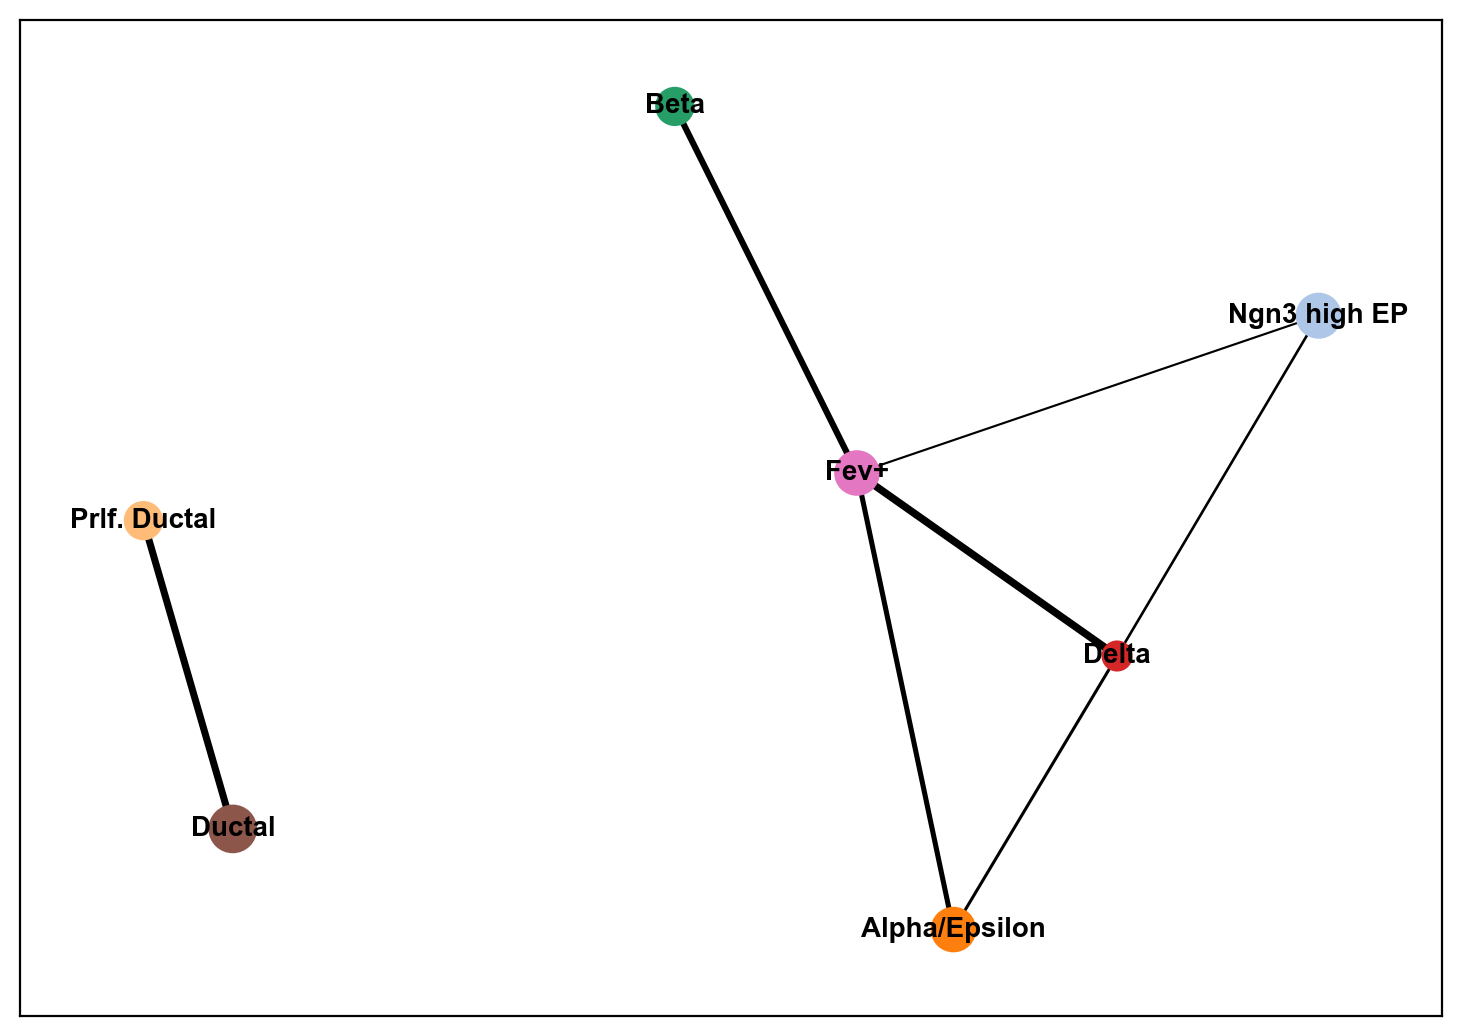

In [24]:
sc.tl.paga(endo, groups="cell_type")
sc.pl.paga(endo, threshold=0.1, node_size_scale=1.5, fontsize=10)

               Alpha/Epsilon  Beta  Delta  Ductal  Fev+  Ngn3 high EP  \
Alpha/Epsilon           0.00  0.09   0.15    0.00  0.24          0.02   
Beta                    0.09  0.00   0.02    0.00  0.30          0.00   
Delta                   0.15  0.02   0.00    0.00  0.36          0.13   
Ductal                  0.00  0.00   0.00    0.00  0.00          0.10   
Fev+                    0.24  0.30   0.36    0.00  0.00          0.10   
Ngn3 high EP            0.02  0.00   0.13    0.10  0.10          0.00   
Prlf. Ductal            0.00  0.00   0.00    0.34  0.00          0.03   

               Prlf. Ductal  
Alpha/Epsilon          0.00  
Beta                   0.00  
Delta                  0.00  
Ductal                 0.34  
Fev+                   0.00  
Ngn3 high EP           0.03  
Prlf. Ductal           0.00  


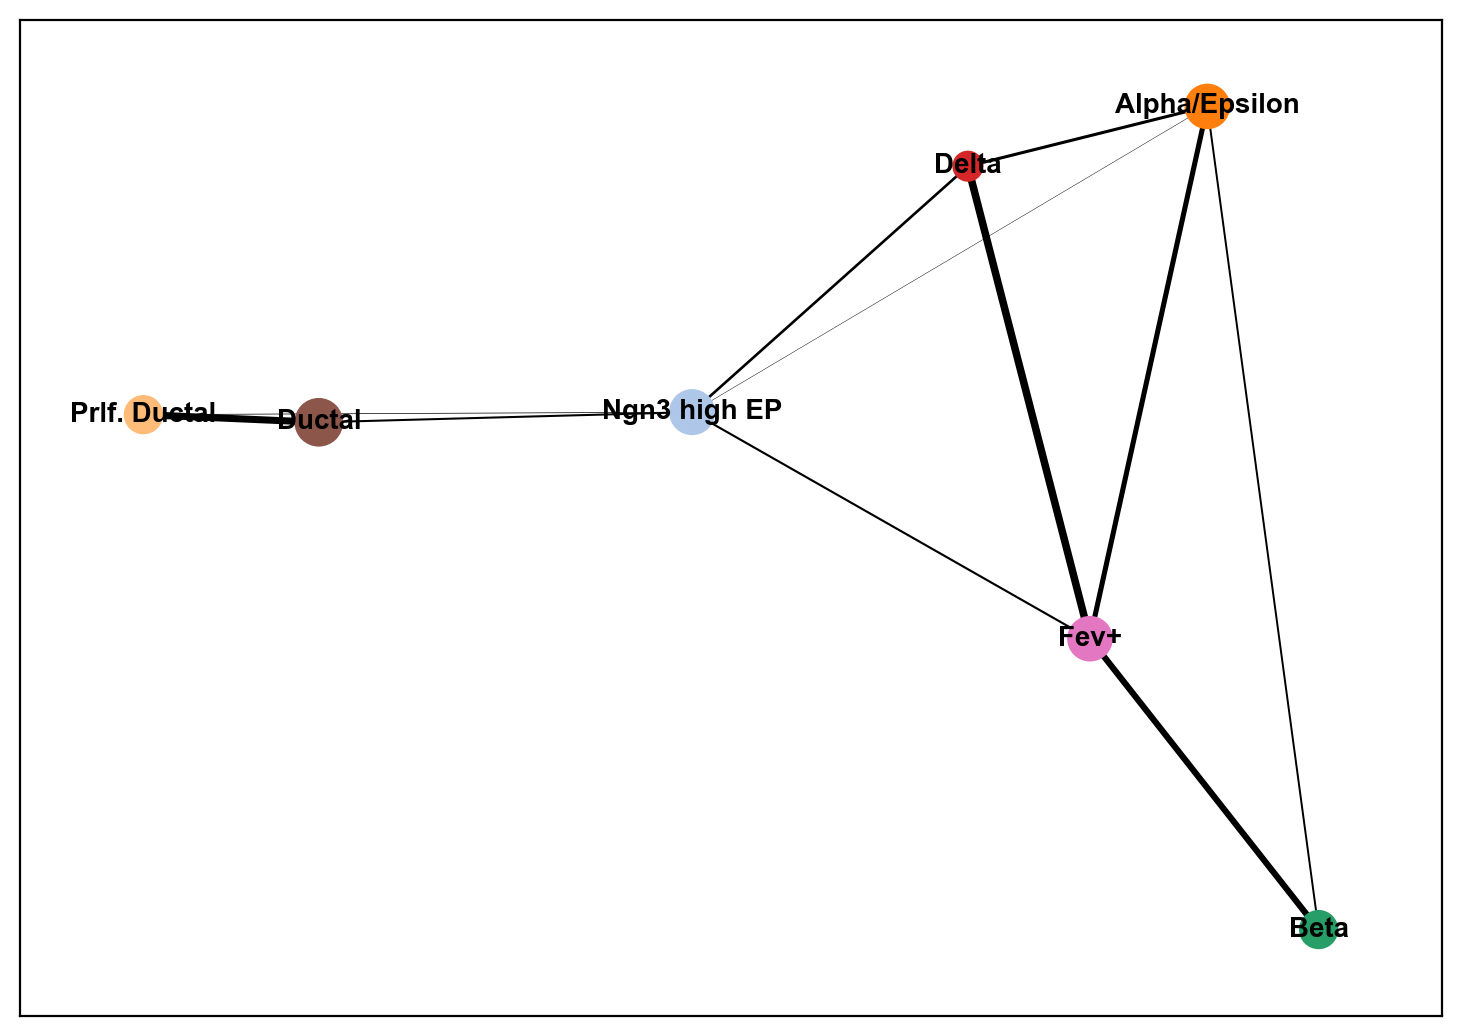

In [25]:
cats = endo.obs["cell_type"].cat.categories
conn = pd.DataFrame(endo.uns["paga"]["connectivities"].toarray(), index=cats, columns=cats).round(2)
print(conn)

sc.pl.paga(endo, threshold=0.02, node_size_scale=1.5, fontsize=10)

Diffusion pseudotime

computing Diffusion Maps using n_comps=15(=n_dcs)
computing transitions
    finished (0:00:00)
    eigenvalues of transition matrix
    [1.         0.99871063 0.99072903 0.98335546 0.9786394  0.9773793
     0.9738664  0.96571016 0.9595941  0.9459008  0.9347419  0.9274633
     0.9246288  0.9184177  0.91619515]
    finished (0:00:00)
computing Diffusion Pseudotime using n_dcs=10
    finished (0:00:00)


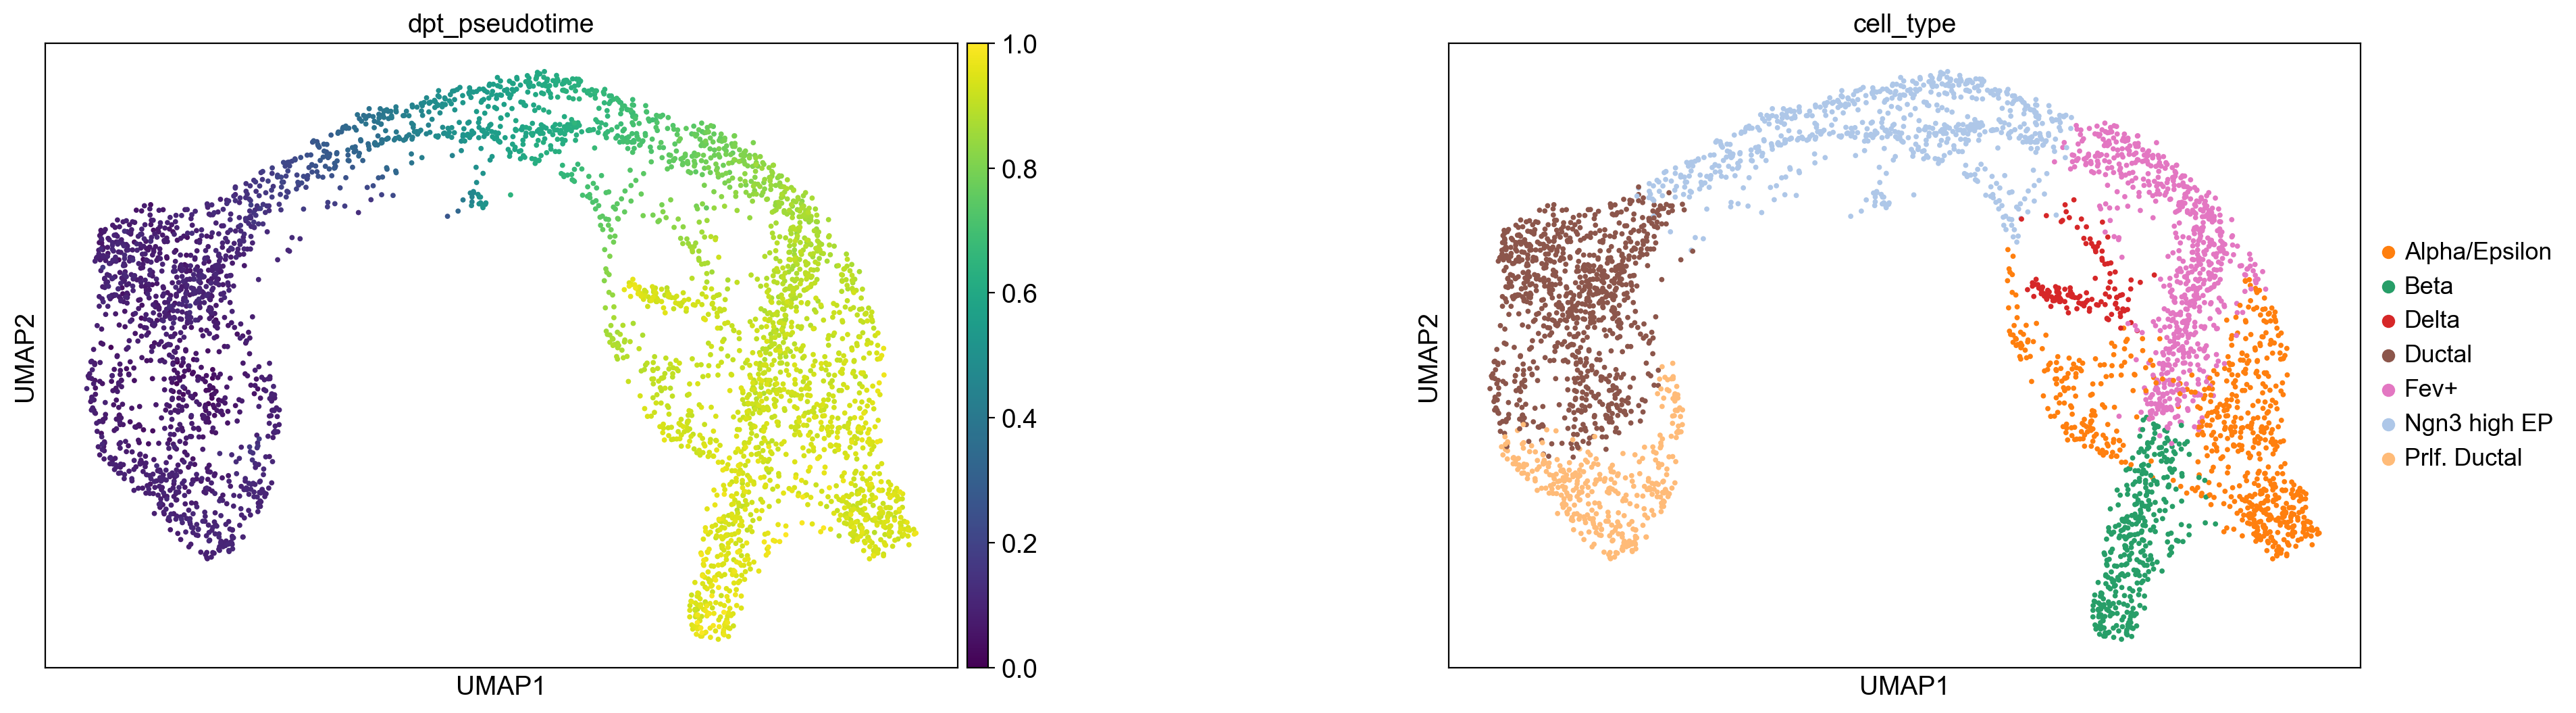

In [26]:
sc.tl.diffmap(endo)
dc1 = endo.obsm["X_diffmap"][:, 1]
ct = endo.obs["cell_type"].astype(str).to_numpy()

if dc1[ct == "Beta"].mean() < dc1[ct == "Ductal"].mean():
    dc1 = -dc1
endo.uns["iroot"] = int(np.argmin(np.where(ct == "Ductal", dc1, np.inf)))

sc.tl.dpt(endo)
sc.pl.umap(endo, color=["dpt_pseudotime", "cell_type"], wspace=0.4)

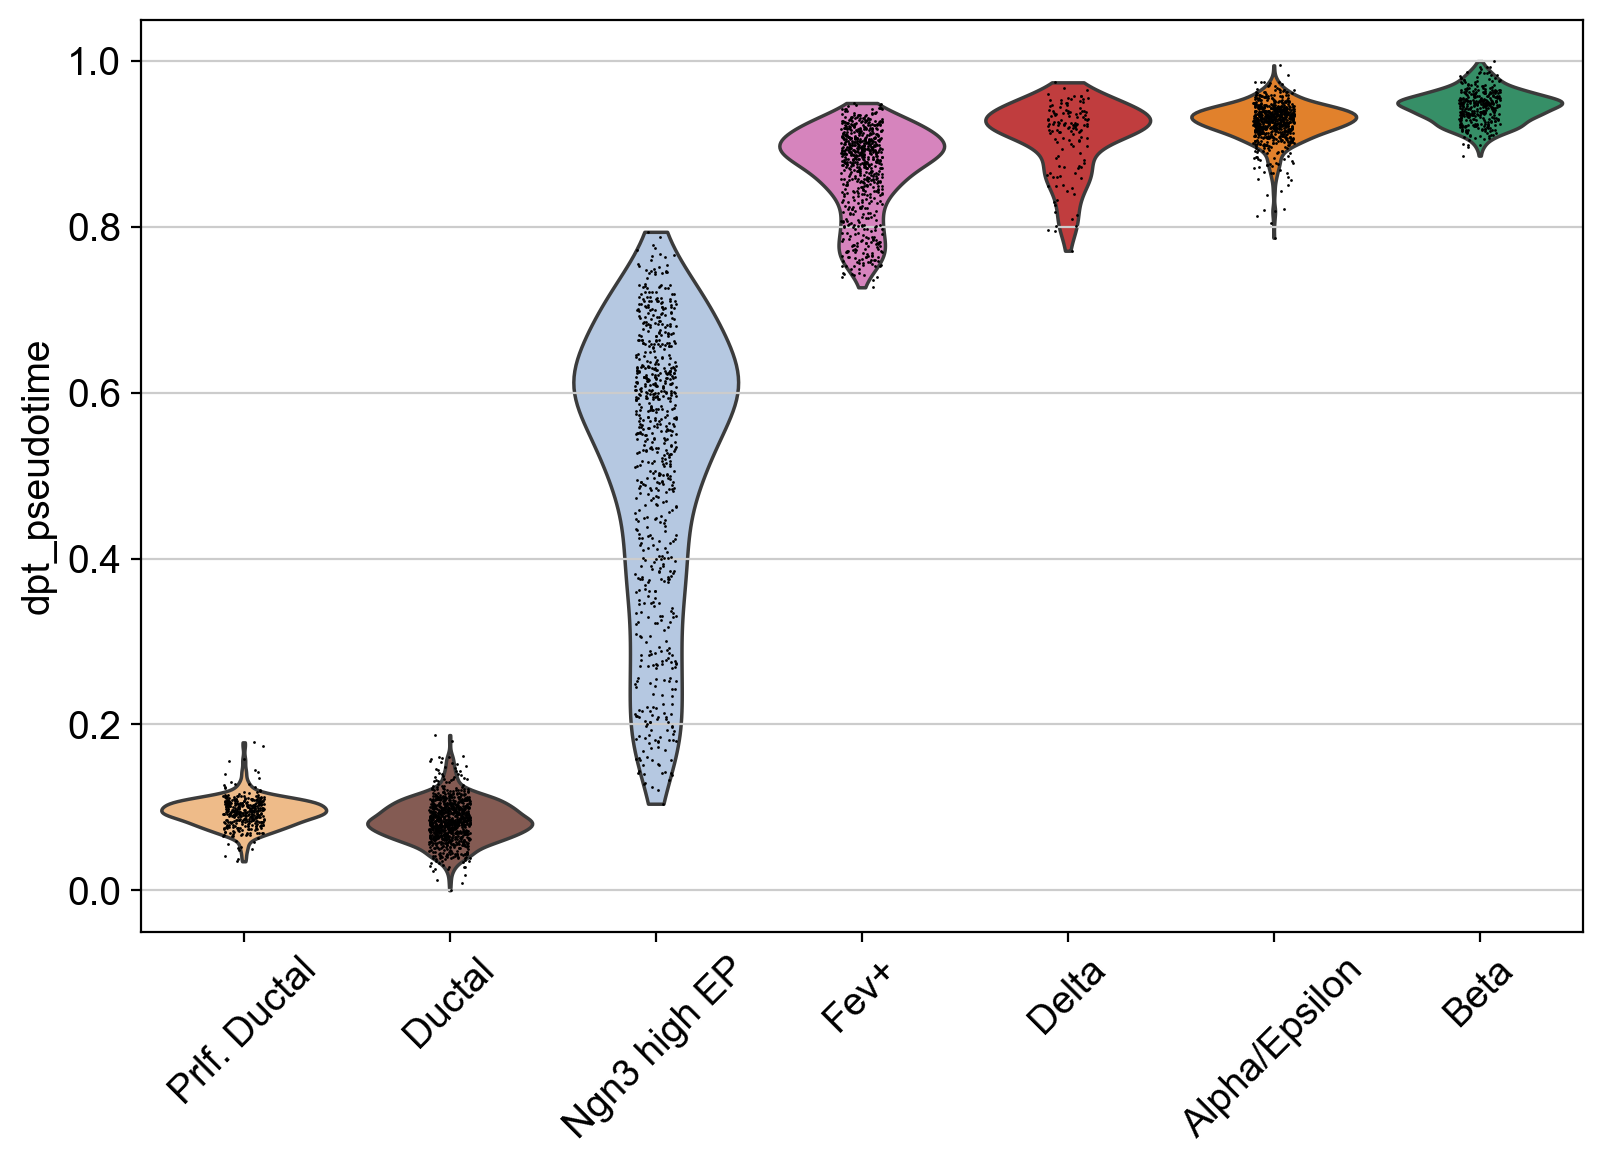

In [27]:
order = ["Prlf. Ductal", "Ductal", "Ngn3 high EP", "Fev+", "Delta", "Alpha/Epsilon", "Beta"]
sc.pl.violin(endo, "dpt_pseudotime", groupby="cell_type", order=order, rotation=45)

In [28]:
adata.write("data/E15_5_processed.h5ad")
endo.write("data/E15_5_endocrine_trajectory.h5ad")